# 03 · Baselines, candidatos y LLM por *prompting*

Todas las familias se evalúan con **el mismo protocolo**, para que la comparación sea justa:

| Elemento | Valor |
|---|---|
| Datos | Caché de la variante R (419 features), período de entrenamiento/CV 2018-01 → 2019-09. La prueba (nov-2019) no se toca aquí |
| Validación | `EmbargoTimeSeriesSplit`: 4 pliegues de 2 meses con ventana expansiva y **30 días de embargo** (justificación: deriva temporal y etiqueta que mira 30 días al futuro; ver la EDA) |
| Métrica | **PR-AUC por evento** (episodios de 30 días repetibles; acierto si la falla llega 7–30 días después). Auxiliar: AP por fila |
| Entrenamiento | Todos los discos que fallan + **15 % de los discos sanos** (por disco, determinista). La validación usa **todas** sus filas |
| Semilla | 42 en todo (`pl.SEMILLA`) |
| Registro | Cada familia es una corrida de MLflow con parámetros, semilla, datos (tabla, corte, SHA-256), métricas (train, CV media ± std, brecha, segundos), tags (`fase`, `familia`, `git_commit`) y el `Pipeline` con firma y ejemplo de entrada |

**Baselines** (`fase=baseline`): dummy (prior), regla de umbral sobre **R_198** (EDA) y logística **sin features temporales** (solo el valor del día).
**Candidatos** (`fase=candidato`), con hiperparámetros por defecto:

| Familia | Modelo | Por qué |
|---|---|---|
| Lineal regularizado | Logística L2 con `class_weight="balanced"` (cuML, GPU) | Referencia interpretable; usa `log1p` + imputación + escala |
| *Bagging* | Random forest de XGBoost (`XGBRFClassifier`, GPU) | Árboles profundos promediados sobre bootstrap; acepta NaN |
| *Boosting* | XGBoost (`hist`, GPU), `scale_pos_weight="balanced"` | Estado del arte en datos tabulares con faltantes y colas largas |
| Red neuronal | MLP 256-128 con dropout (PyTorch + skorch) | Captura interacciones no lineales sobre features escaladas |
| *State of the art* | **TabPFN-3.5-Fast** (modelo fundacional tabular, Prior Labs) | Aprende "en contexto" sin entrenar. Contexto de 20.000 filas: en la medición, 100.000 no mejoraron y multiplicaban el tiempo de predicción. Corre en la otra GPU con el mismo protocolo |
| LLM por *prompting* | Gemini (`gemini-3.8-flash`, API gratuita) | Prueba si un LLM general razona sobre telemetría SMART |

In [1]:
import os, sys, json, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
from sklearn.metrics import average_precision_score, roc_auc_score

sys.path.insert(0, str(Path.cwd().parent))
from src import datos, pipeline as pl, experimentos as exp

load_dotenv("../.env")  # GEMINI_API_KEY (no se imprime)
pd.set_option("display.width", 220, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid", context="notebook")

DATOS = Path(os.environ.get("DATOS_DIR", "/datos"))
SNAPSHOT, CACHE = DATOS / "obt_mc1", DATOS / "cache_R"
OOF_DIR = DATOS / "oof" / "03"; OOF_DIR.mkdir(parents=True, exist_ok=True)
FIG = Path("../docs/figuras"); FIG.mkdir(parents=True, exist_ok=True)
SEMILLA, FRAC_SANOS = pl.SEMILLA, 0.15
T0 = time.time()

mlflow = pl.configurar_mlflow()
manifiesto = datos.leer_manifiesto(SNAPSHOT)
META_DATOS = datos.metadatos_dataset(SNAPSHOT)
eda = json.loads(Path("../docs/eda_decisiones.json").read_text())
print("MLflow:", mlflow.get_tracking_uri(), "· experimento:", pl.NOMBRE_EXPERIMENTO, "· commit:", pl.commit_git())
META_DATOS

MLflow: http://mlflow:5000 · experimento: ssd-failure-mc1 · commit: 4afd99f2535efca2a71d801975621491d168b58c


{'datos_tabla_origen': 'WXVGCFK_QF18928_S_CDATOS_PSET2_SNOWFLAKE_SHARE_1792893424527.S_CDATOS_PSET2_OBT.OBT_MC1_RN',
 'datos_fecha_corte': '2019-12-30',
 'datos_sha256': 'c0b1ea5c055579e01023c006e04a040686c8a32a4f8512ceddb7070b0f2a111c',
 'datos_filas': '110091780'}

## 1. Datos y pliegues

In [2]:
SPLITTER = pl.EmbargoTimeSeriesSplit(n_splits=4, meses_validacion=2, embargo_dias=30)
# Protocolo común (src/experimentos.py): mismo que usa scripts/correr_familia.py en la otra GPU
CTX = exp.preparar(DATOS, OOF_DIR, splitter=SPLITTER, frac_sanos=FRAC_SANOS)
train, COLUMNAS = CTX.train, CTX.columnas

filas = []
meta = train[["SSD_KEY", "OBSERVATION_DATE", "DAYS_TO_FAILURE", "TARGET_30D"]]
for i, (itr, iva) in enumerate(SPLITTER.split(meta)):
    tr, va = meta.iloc[itr], meta.iloc[iva]
    filas.append({"pliegue": i, "train_hasta": tr["OBSERVATION_DATE"].max().date(),
                  "val_desde": va["OBSERVATION_DATE"].min().date(), "val_hasta": va["OBSERVATION_DATE"].max().date(),
                  "filas_train": len(itr), "filas_train_entrenadas": len(pl.muestra_por_disco(tr, FRAC_SANOS)),
                  "filas_val": len(iva), "eventos_val": pl.eventos_anticipables(va["SSD_KEY"], va["DAYS_TO_FAILURE"])})
pliegues = pd.DataFrame(filas).set_index("pliegue")
print(f"{len(train):,} filas · {len(COLUMNAS)} features · semilla {SEMILLA} · fracción de sanos al entrenar {FRAC_SANOS}")
pliegues

100,603,393 filas · 419 features · semilla 42 · fracción de sanos al entrenar 0.15


,train_hasta,val_desde,val_hasta,filas_train,filas_train_entrenadas,filas_val,eventos_val
pliegue,,,,,,,
0,2019-01-01,2019-02-01,2019-03-31,53673091,8453718,10381840,801
1,2019-03-01,2019-04-01,2019-05-31,64024821,10143847,10683186,1850
2,2019-05-01,2019-06-01,2019-07-31,74701241,12148945,10225924,2821
3,2019-07-01,2019-08-01,2019-09-30,85180358,14475461,10378208,3305


Cada pliegue valida sobre **miles de eventos** (riesgo T1 del PSet #1: con pocos eventos la métrica sería ruido). El
embargo de 30 días entre `train_hasta` y `val_desde` se verifica además con una aserción dentro de `evaluar_cv`.

In [3]:
RESULTADOS = {}

def correr(nombre, fase, familia, params=None, modelo=None, tags=None):
    # Misma CV, registro en MLflow y OOF en disco (src/experimentos.py). Si ya corrió, se reutiliza.
    RESULTADOS[nombre] = exp.correr(CTX, nombre, fase, familia, params=params, modelo=modelo, tags=tags)
    return RESULTADOS[nombre]

## 2. Baselines

In [4]:
correr("dummy", "baseline", "dummy")
correr("regla_" + eda["atributo_regla"], "baseline", "regla", {"atributo": eda["atributo_regla"]})
correr("sin_temporales", "baseline", "sin_temporales")

dummy: ya registrado (run bab0adc8), se reutiliza


regla_R_198: ya registrado (run dd003179), se reutiliza


sin_temporales: ya registrado (run cf2a0160), se reutiliza


{'nombre': 'sin_temporales',
 'fase': 'baseline',
 'familia': 'sin_temporales',
 'run_id': 'cf2a0160605548a7a32618a288513e2e',
 'cv_pliegues': [0.0013704023110563681,
  0.018123522285328163,
  0.008392697196607323,
  0.008594835137238995],
 'train_pliegues': [0.016973196379318836,
  0.013756313811360428,
  0.010767121833374315,
  0.011423470772711107],
 'cv_pr_auc_evento_media': 0.009120364232557712,
 'cv_pr_auc_evento_std': 0.006878091907235164,
 'train_pr_auc_evento': 0.013230025699191173,
 'brecha_train_cv': 0.004109661466633462,
 'cv_ap_fila_media': 0.013039100788859118,
 'segundos_entrenamiento': 819.325374243781}

## 3. Candidatos (hiperparámetros por defecto)

In [5]:
# PSET3_OMITIR permite posponer familias (p. ej. tabpfn mientras se mide su costo); al re-ejecutar el
# notebook, lo ya registrado se reutiliza y solo corre lo que falta.
OMITIR = {f for f in os.getenv("PSET3_OMITIR", "").split(",") if f}
for familia in ("logistica", "bosque", "xgboost", "mlp", "tabpfn"):
    if familia in OMITIR:
        print(f"{familia}: omitida en esta ejecución (PSET3_OMITIR)")
        continue
    correr(familia, "candidato", familia)

logistica: ya registrado (run f479ab79), se reutiliza


bosque: ya registrado (run 8434adce), se reutiliza


xgboost: ya registrado (run 276e4b75), se reutiliza


2026/11/16 18:57:24 WARNING mlflow.tracking.context.registry: Encountered unexpected error during resolving tags: 'getpwuid(): uid not found: 4454'


2026/11/16 18:57:24 WARNING mlflow.tracking.context.registry: Encountered unexpected error during resolving tags: 'getpwuid(): uid not found: 4454'


2026/11/16 18:57:28 WARNING mlflow.tracking.context.registry: Encountered unexpected error during resolving tags: 'getpwuid(): uid not found: 4454'


2026/11/16 18:57:28 INFO mlflow.models.model: Found the following environment variables used during model inference: [ANTHROPIC_API_KEY, GEMINI_API_KEY]. Please check if you need to set them when deploying the model. To disable this message, set environment variable `MLFLOW_RECORD_ENV_VARS_IN_MODEL_LOGGING` to `false`.


🏃 View run mlp at: http://mlflow:5000/#/experiments/2/runs/b6bed58d5dff429c83b474b8dcaf0acf
🧪 View experiment at: http://mlflow:5000/#/experiments/2


mlp: CV 0.0109 ± 0.0062 · train 0.1532 · 67.7 min · run b6bed58d


tabpfn: omitida en esta ejecución (PSET3_OMITIR)


### 3.1 Ablación: ¿aporta `N_CRITICAL_DEGRADING_30D`?

En el notebook 02 la feature derivada, sola, era más débil que su mejor componente. Aquí se mide su aporte **dentro
del modelo**: la misma familia con la feature anulada (lista de atributos críticos vacía → columna constante).

In [6]:
for familia in ("logistica", "xgboost"):
    sin_degr = pl.construir_modelo(familia, seed=SEMILLA).set_params(prep__derivadas__atributos=())
    correr(f"{familia}_sin_degradacion", "candidato", familia, modelo=sin_degr,
           tags={"ablacion": "sin N_CRITICAL_DEGRADING_30D"})

[2026-11-16 19:04:21.602] [CUML] [warning] L-BFGS line search failed (code 3); stopping at the last valid step


[2026-11-16 19:17:57.752] [CUML] [warning] L-BFGS line search failed (code 3); stopping at the last valid step


[2026-11-16 19:33:16.908] [CUML] [warning] L-BFGS line search failed (code 3); stopping at the last valid step


[2026-11-16 19:49:40.458] [CUML] [warning] L-BFGS line search failed (code 3); stopping at the last valid step


2026/11/16 20:01:14 WARNING mlflow.tracking.context.registry: Encountered unexpected error during resolving tags: 'getpwuid(): uid not found: 4454'


2026/11/16 20:01:18 WARNING mlflow.tracking.context.registry: Encountered unexpected error during resolving tags: 'getpwuid(): uid not found: 4454'


... (3 outputs left out)

2026/11/16 20:50:10 WARNING mlflow.tracking.context.registry: Encountered unexpected error during resolving tags: 'getpwuid(): uid not found: 4454'


2026/11/16 20:50:10 WARNING mlflow.tracking.context.registry: Encountered unexpected error during resolving tags: 'getpwuid(): uid not found: 4454'


🏃 View run xgboost_sin_degradacion at: http://mlflow:5000/#/experiments/2/runs/29e497b6538748e3be827511044693cb
🧪 View experiment at: http://mlflow:5000/#/experiments/2


xgboost_sin_degradacion: CV 0.0090 ± 0.0039 · train 0.2208 · 48.8 min · run 29e497b6


## 4. Comparación

In [7]:
RESULTADOS = exp.resultados(OOF_DIR)  # incluye TabPFN, que corre en la otra GPU (scripts/correr_familia.py)
tabla = (pd.DataFrame(RESULTADOS.values()).set_index("nombre")
         [["fase", "familia", "train_pr_auc_evento", "cv_pr_auc_evento_media", "cv_pr_auc_evento_std",
           "brecha_train_cv", "cv_ap_fila_media", "segundos_entrenamiento"]])
dummy_cv = tabla.loc["dummy", "cv_pr_auc_evento_media"]
regla_cv = tabla.loc["regla_" + eda["atributo_regla"], "cv_pr_auc_evento_media"]
tabla["x_dummy"] = tabla["cv_pr_auc_evento_media"] / dummy_cv
tabla["supera_regla_por_mas_de_1std"] = tabla["cv_pr_auc_evento_media"] - tabla["cv_pr_auc_evento_std"] > regla_cv
tabla["minutos"] = tabla["segundos_entrenamiento"] / 60
tabla.sort_values("cv_pr_auc_evento_media", ascending=False).drop(columns="segundos_entrenamiento")

,fase,familia,train_pr_auc_evento,cv_pr_auc_evento_media,cv_pr_auc_evento_std,brecha_train_cv,cv_ap_fila_media,x_dummy,supera_regla_por_mas_de_1std,minutos
nombre,,,,,,,,,,
regla_R_198,baseline,regla,0.0091,0.0155,0.0181,-0.0064,0.0206,5.0657,False,10.6706
bosque,candidato,bosque,0.1895,0.0120,0.0097,0.1775,0.0176,3.9351,False,35.5652
mlp,candidato,mlp,0.1532,0.0109,0.0062,0.1423,0.0154,3.5723,False,23.0365
xgboost,candidato,xgboost,0.2192,0.0099,0.0045,0.2093,0.0135,3.2231,False,23.4995
sin_temporales,baseline,sin_temporales,0.0132,0.0091,0.0069,0.0041,0.0130,2.9809,False,13.6554
xgboost_sin_degradacion,candidato,xgboost,0.2208,0.0090,0.0039,0.2118,0.0122,2.9535,False,24.4352
logistica,candidato,logistica,0.0152,0.0084,0.0048,0.0068,0.0138,2.7329,False,71.1940
logistica_sin_degradacion,candidato,logistica,0.0144,0.0082,0.0046,0.0062,0.0134,2.6762,False,23.3287
dummy,baseline,dummy,0.0009,0.0031,0.0018,-0.0022,0.0044,1.0000,False,12.4103


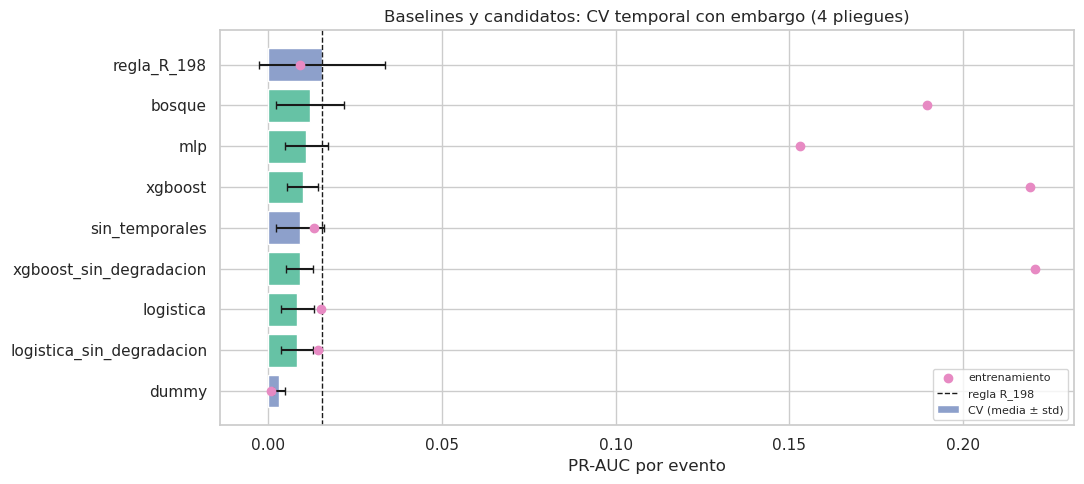

In [8]:
orden = tabla.sort_values("cv_pr_auc_evento_media").index
colores = tabla.loc[orden, "fase"].map({"baseline": "#8DA0CB", "candidato": "#66C2A5"})
fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(orden, tabla.loc[orden, "cv_pr_auc_evento_media"], xerr=tabla.loc[orden, "cv_pr_auc_evento_std"],
        color=colores, capsize=3, label="CV (media ± std)")
ax.scatter(tabla.loc[orden, "train_pr_auc_evento"], orden, color="#E78AC3", zorder=3, label="entrenamiento")
ax.axvline(regla_cv, color="k", ls="--", lw=1, label=f"regla {eda['atributo_regla']}")
ax.set_xlabel("PR-AUC por evento"); ax.set_title("Baselines y candidatos: CV temporal con embargo (4 pliegues)")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "03_comparacion_cv.png", dpi=150); plt.show()

In [9]:
# Diagnóstico de sobreajuste: brecha train − CV relativa a la CV
diag = tabla[["train_pr_auc_evento", "cv_pr_auc_evento_media", "brecha_train_cv"]].copy()
diag["brecha_relativa"] = diag["brecha_train_cv"] / diag["cv_pr_auc_evento_media"]
diag["diagnóstico"] = np.select(
    [diag["brecha_relativa"] > 1.0, diag["brecha_relativa"] > 0.3],
    ["sobreajuste fuerte (train > 2× CV)", "sobreajuste moderado"], "sin sobreajuste relevante")
diag.sort_values("cv_pr_auc_evento_media", ascending=False)

,train_pr_auc_evento,cv_pr_auc_evento_media,brecha_train_cv,brecha_relativa,diagnóstico
nombre,,,,,
regla_R_198,0.0091,0.0155,-0.0064,-0.4111,sin sobreajuste relevante
bosque,0.1895,0.0120,0.1775,14.7423,sobreajuste fuerte (train > 2× CV)
mlp,0.1532,0.0109,0.1423,13.0154,sobreajuste fuerte (train > 2× CV)
xgboost,0.2192,0.0099,0.2093,21.2272,sobreajuste fuerte (train > 2× CV)
sin_temporales,0.0132,0.0091,0.0041,0.4506,sobreajuste moderado
xgboost_sin_degradacion,0.2208,0.0090,0.2118,23.4358,sobreajuste fuerte (train > 2× CV)
logistica,0.0152,0.0084,0.0068,0.8147,sobreajuste moderado
logistica_sin_degradacion,0.0144,0.0082,0.0062,0.7616,sobreajuste moderado
dummy,0.0009,0.0031,-0.0022,-0.7182,sin sobreajuste relevante


## 5. LLM por *prompting* (Gemini)

Un LLM no puede puntuar las ~10M filas de un pliegue de validación (sería lentísimo y, en el nivel gratuito, imposible).
Por eso se evalúa sobre una **submuestra estratificada del último pliegue de validación**: 100 disco-días positivos
(fallan en ≤ 30 días) y 400 negativos, elegidos con la semilla. **Todos los modelos se comparan sobre esas mismas 500
filas** con métricas por fila (AP y ROC-AUC), usando sus predicciones *out-of-fold* (ningún modelo vio esas filas).

El LLM recibe solo features (edad y 10 atributos SMART con su valor del día, media de 30 días y cambios de 7 y 30 días;
nunca la etiqueta ni el identificador) y devuelve probabilidades en JSON con esquema fijo. Las respuestas se guardan en
disco: re-ejecutar el notebook no vuelve a llamar a la API.

In [10]:
HACER_LLM = "llm" not in OMITIR
if HACER_LLM:
    from src import llm

    # La misma muestra (y la misma caché) que scripts/correr_llm.py, que puede llenarla en paralelo
    pos_llm = llm.muestra_evaluacion(meta, SPLITTER, seed=SEMILLA, n_pos=100, n_neg=400)
    X_llm, y_llm = train.iloc[pos_llm], meta["TARGET_30D"].to_numpy()[pos_llm]
    iva_u = list(SPLITTER.split(meta))[-1][1]
    sel = np.searchsorted(iva_u, pos_llm)     # posiciones dentro del último pliegue (para leer las OOF)

    t = time.time()
    r_llm = llm.predecir(X_llm, DATOS / "llm_cache" / llm.MODELO_LLM, seed=SEMILLA)
    print(f"Gemini: {r_llm.llamadas_api} llamadas nuevas, {r_llm.respuestas_cache} desde caché, "
          f"{time.time()-t:.0f} s · tokens entrada/salida/razonamiento: {r_llm.tokens_entrada:,} / "
          f"{r_llm.tokens_salida:,} / {r_llm.tokens_razonamiento:,} · lotes fallidos: {r_llm.lotes_fallidos}")
else:
    print("LLM omitido en esta ejecución (PSET3_OMITIR); se agrega al re-ejecutar el notebook")

LLM omitido en esta ejecución (PSET3_OMITIR); se agrega al re-ejecutar el notebook


In [11]:
if HACER_LLM:
    # Predicciones OOF de cada modelo sobre las mismas 500 filas (último pliegue)
    comparacion = {"llm_gemini": r_llm.probabilidades}
    for nombre in RESULTADOS:
        oof = pd.read_parquet(OOF_DIR / f"{nombre}.parquet")
        comparacion[nombre] = oof.loc[oof["pliegue"] == oof["pliegue"].max(), "score"].to_numpy()[sel]

    ok = ~np.isnan(r_llm.probabilidades)
    filas = []
    for nombre, s in comparacion.items():
        filas.append({"modelo": nombre, "AP_fila_muestra": average_precision_score(y_llm[ok], s[ok]),
                      "ROC_AUC_muestra": roc_auc_score(y_llm[ok], s[ok])})
    muestra_tabla = pd.DataFrame(filas).set_index("modelo").sort_values("AP_fila_muestra", ascending=False)
    print(f"Muestra: {ok.sum()} filas con respuesta del LLM, {int(y_llm[ok].sum())} positivas "
          f"(AP de un modelo al azar = {y_llm[ok].mean():.2f})")
    muestra_tabla
else:
    print("LLM omitido en esta ejecución (PSET3_OMITIR); se agrega al re-ejecutar el notebook")

LLM omitido en esta ejecución (PSET3_OMITIR); se agrega al re-ejecutar el notebook


In [12]:
if HACER_LLM:
    # Registro del LLM en MLflow: no es un estimador entrenable (llama a una API externa), así que se registran el
    # prompt, la configuración, las predicciones y las métricas sobre la muestra, en lugar de un modelo serializado.
    import hashlib
    with mlflow.start_run(run_name="llm_gemini") as run:
        mlflow.log_params({"semilla": SEMILLA, "modelo_llm": llm.MODELO_LLM, "casos": int(len(sel)),
                           "positivos_muestra": 100, "casos_por_lote": 20, "temperatura": 0.0,
                           "atributos": ",".join(map(str, llm.ATRIBUTOS_LLM)),
                           "prompt_sha256": hashlib.sha256(llm.INSTRUCCIONES.encode()).hexdigest(),
                           "muestra": "estratificada del ultimo pliegue de validacion", **META_DATOS})
        mlflow.log_metrics({"ap_fila_muestra": muestra_tabla.loc["llm_gemini", "AP_fila_muestra"],
                            "roc_auc_muestra": muestra_tabla.loc["llm_gemini", "ROC_AUC_muestra"],
                            "llamadas_api": r_llm.llamadas_api, "segundos_api": r_llm.segundos_api,
                            "tokens_entrada": r_llm.tokens_entrada, "tokens_salida": r_llm.tokens_salida,
                            "tokens_razonamiento": r_llm.tokens_razonamiento, "costo_usd": 0.0,
                            "respuestas_validas": int(ok.sum())})
        mlflow.set_tags({"fase": "candidato", "familia": "llm", "git_commit": pl.commit_git(),
                         "modelo_registrado": "no: LLM externo por API; se registran prompt y predicciones"})
        mlflow.log_text(llm.INSTRUCCIONES, "prompt_sistema.txt")
        mlflow.log_text(json.dumps([{"id": i, **llm.resumen_caso(f)} for i, (_, f) in enumerate(X_llm.head(3).iterrows())],
                                   indent=1), "ejemplo_entrada.json")
        pd.DataFrame({"y": y_llm, **comparacion}).to_csv(OOF_DIR / "muestra_llm.csv", index=False)
        mlflow.log_artifact(str(OOF_DIR / "muestra_llm.csv"))
        print("run", run.info.run_id)
else:
    print("LLM omitido en esta ejecución (PSET3_OMITIR); se agrega al re-ejecutar el notebook")

LLM omitido en esta ejecución (PSET3_OMITIR); se agrega al re-ejecutar el notebook


## 6. Los tres mejores pasan a tuning

In [13]:
candidatos = tabla[(tabla["fase"] == "candidato") & ~tabla.index.str.contains("sin_degradacion")]
top = candidatos.sort_values("cv_pr_auc_evento_media", ascending=False).head(3)
primero = top.iloc[0]
top = top.assign(diferencia_vs_primero=primero["cv_pr_auc_evento_media"] - top["cv_pr_auc_evento_media"],
                 dentro_de_1std_del_primero=lambda d: d["diferencia_vs_primero"] <= primero["cv_pr_auc_evento_std"])
Path("../docs/candidatos_top3.json").write_text(json.dumps(
    {"familias": top["familia"].tolist(), "cv_pr_auc_evento_media": top["cv_pr_auc_evento_media"].round(5).tolist(),
     "cv_pr_auc_evento_std": top["cv_pr_auc_evento_std"].round(5).tolist(), "frac_sanos_train": FRAC_SANOS,
     "dataset_sha256": manifiesto["dataset_sha256"]}, indent=2))
print(f"Tiempo total del notebook: {(time.time()-T0)/60:.1f} min")
top[["familia", "cv_pr_auc_evento_media", "cv_pr_auc_evento_std", "diferencia_vs_primero", "dentro_de_1std_del_primero"]]

Tiempo total del notebook: 181.0 min


,familia,cv_pr_auc_evento_media,cv_pr_auc_evento_std,diferencia_vs_primero,dentro_de_1std_del_primero
nombre,,,,,
bosque,bosque,0.0120,0.0097,0.0000,True
mlp,mlp,0.0109,0.0062,0.0011,True
xgboost,xgboost,0.0099,0.0045,0.0022,True
